# Sequential DDPG and RegControl paper figures

## Purpose

This notebook draws seven figures that compare sequential DDPG with native RegControl on two feeders and two loading settings.
It only reads saved results; it never trains or evaluates.
Results describe the saved validation split. They do not establish convergence or general performance.

## Assumptions

Each item states how this notebook reads the figure request. Cite the item number when an assumption needs to change.

1. **DDPG.** "DDPG" means sequential DDPG with the main reward setting: α = 0 and β = 10⁻⁵ (`band_b1e-05` runs).
2. **Feeders.** "IEEE 37-bus" means the modified feeder `ieee37mod`. The standard IEEE 37-bus feeder is not used.
3. **Split.** Every figure uses the validation split. The test split stays unread.
4. **Seeds.** Each DDPG value averages training seeds 0 to 9. The seed list follows a fixed rule: the first ten non-negative integers.
5. **Seed retention.** No seed is dropped or replaced because of its results. Unfavourable results stay in every figure.
6. **Seed spread.** Error bars and bands show ±1 sample standard deviation across seeds. They are not confidence intervals.
7. **RegControl.** RegControl is deterministic and has one run per case. Both controllers use the same evaluation weights.
8. **Combined cost.** Daily combined cost equals daily voltage-excursion cost plus β times daily tap steps, with β = 10⁻⁵.
9. **Ratios.** Figure 2 divides mean daily metrics. It shows no ratio when the RegControl mean is zero.
10. **Selected run.** Figures 3 and 4 show DDPG seed 0, the first seed, on ERCOT day 2024-10-08.
11. **Selected day rule.** That day is the selected day of the existing ERCOT notebooks. It was fixed before this notebook existed.
12. **Loading in Figures 3 and 4.** These figures use ERCOT loading only. Random loading has no daily shape.
13. **Tap positions.** Figure 3 shows executed integer positions as aligned heatmaps. Position 16 is neutral.
14. **Daily values.** Figures 5 and 6 average the DDPG daily cost across seeds on each day.
15. **Figure 7.** The supplementary figure uses ERCOT loading and four separately trained settings, with seeds 0 to 9 each.
16. **Individual seeds.** The per-seed table near the end holds the individual-seed results.
17. **Display.** Costs appear in units of 10⁻³. Figures stay embedded in this notebook; it exports no image files.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[0]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/).")
sys.path.insert(0, str(ROOT / "src"))

from common.paper_figures import (
    load_case,
    plot_daily_savings,
    plot_day_operation,
    plot_day_voltage,
    plot_overall,
    plot_paired_days,
    plot_preferences,
    plot_relative,
    show_conclusions,
    show_preference_summary,
    show_seed_table,
    show_summary_table,
)

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells.
Every change here only changes the display.
Make sure each listed seed has saved validation results.

In [2]:
SEEDS = list(range(10))  # Training seeds in every mean.
SPLIT = "validation"  # Evaluation split.
RUN_NAME = "band_b1e-05"  # Main setting before _seed<seed>.
BETA = 1e-5  # Evaluation weight per tap step.
CASES = [  # Feeder, loading, training days per run.
    ("ieee13", "random", 1000),
    ("ieee37mod", "random", 1000),
    ("ieee13", "ercot", 7985),
    ("ieee37mod", "ercot", 7985),
]
DAY_LOADING = "ercot"  # Loading shown in Figures 3 and 4.
PLOT_DAY = 280  # Selected evaluated day by zero-based position.
PLOT_SEED = 0  # DDPG run shown in Figures 3 and 4.
PREFERENCE_LOADING = "ercot"  # Loading shown in Figure 7.
CENTERING = {"deviation": "abs", "alpha": 0.1, "rate": 20.0}  # Nominal-voltage term.
SETTINGS = [  # Letter, legend text, run name, beta, reward overrides.
    ("A", "Main setting: α = 0, β = 10⁻⁵", RUN_NAME, 1e-5, {}),
    ("B", "Add centering: α = 0.1, β = 10⁻⁵", "band_b1e-05_abs_a0.1", 1e-5, CENTERING),
    ("C", "Higher movement weight: α = 0.1, β = 10⁻³", "band_b0.001_abs_a0.1", 1e-3, CENTERING),
    ("D", "Lower movement weight: α = 0.1, β = 10⁻⁷", "band_b1e-07_abs_a0.1", 1e-7, CENTERING),
]
STEPS = [  # Compared settings in the preference summary.
    ("A", "B", "add nominal-voltage centering at fixed β"),
    ("B", "C", "increase the movement weight at fixed α"),
    ("B", "D", "decrease the movement weight at fixed α"),
]

**Units and interfaces.** Voltages use physical p.u. values; tap positions are integer grid indices from 0 to 32.
Tap steps sum absolute executed position changes, including the first movement from neutral.
The voltage-excursion cost is the mean squared excursion outside [0.95, 1.05] p.u.

In [3]:
BASE = {"root": ROOT, "seeds": SEEDS, "split": SPLIT}
cases = {
    (feeder, loading): load_case(BASE, feeder, f"{feeder}-{loading}", RUN_NAME, BETA, {}, days)
    for feeder, loading, days in CASES
}

Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-random/seq_ddpg/band_b1e-05_seed0/, results/ieee13-random/seq_ddpg/band_b1e-05_seed1/, results/ieee13-random/seq_ddpg/band_b1e-05_seed2/, results/ieee13-random/seq_ddpg/band_b1e-05_seed3/, results/ieee13-random/seq_ddpg/band_b1e-05_seed4/, results/ieee13-random/seq_ddpg/band_b1e-05_seed5/, results/ieee13-random/seq_ddpg/band_b1e-05_seed6/, results/ieee13-random/seq_ddpg/band_b1e-05_seed7/, results/ieee13-random/seq_ddpg/band_b1e-05_seed8/, results/ieee13-random/seq_ddpg/band_b1e-05_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 200 days, 4800 hours, and 12 methods.


Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/seq_ddpg/band_b1e-05_seed0/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed1/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed2/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed3/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed4/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed5/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed6/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed7/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed8/, results/ieee37mod-random/seq_ddpg/band_b1e-05_seed9/


Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 200 days, 4800 hours, and 12 methods.
Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-ercot/seq_ddpg/band_b1e-05_seed0/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed1/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed2/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed3/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed4/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed5/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed6/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed7/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed8/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed2/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed3/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed4/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed5/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed6/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed7/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed8/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.


In [4]:
settings = {
    letter: {
        feeder: load_case(BASE, feeder, f"{feeder}-{loading}", run, beta, reward, days)
        for feeder, loading, days in CASES
        if loading == PREFERENCE_LOADING
    }
    for letter, _text, run, beta, reward in SETTINGS
}
descriptions = {letter: text for letter, text, _run, _beta, _reward in SETTINGS}

Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-ercot/seq_ddpg/band_b1e-05_seed0/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed1/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed2/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed3/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed4/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed5/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed6/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed7/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed8/, results/ieee13-ercot/seq_ddpg/band_b1e-05_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed2/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed3/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed4/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed5/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed6/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed7/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed8/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-05_abs_a0.1: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed0/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed1/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed2/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed3/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed4/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed5/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed6/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed7/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed8/, results/ieee13-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-05_abs_a0.1: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed2/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed3/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed4/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed5/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed6/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed7/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed8/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b0.001_abs_a0.1: reward band {'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed0/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed1/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed2/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed3/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed4/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed5/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed6/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed7/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed8/, results/ieee13-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b0.001_abs_a0.1: reward band {'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed2/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed3/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed4/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed5/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed6/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed7/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed8/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-07_abs_a0.1: reward band {'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed0/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed1/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed2/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed3/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed4/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed5/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed6/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed7/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed8/, results/ieee13-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.
Cell band_b1e-07_abs_a0.1: reward band {'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed2/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed3/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed4/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed5/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed6/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed7/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed8/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed9/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 12 methods.


## Argument 1: overall performance

Figures 1 and 2 compare mean daily metrics on all validation days.
Voltage-excursion cost and tap steps appear separately, so the trade-off stays visible.
Across-seed spread describes training runs, not days.

### Figure 1: absolute performance, grouped by loading setting

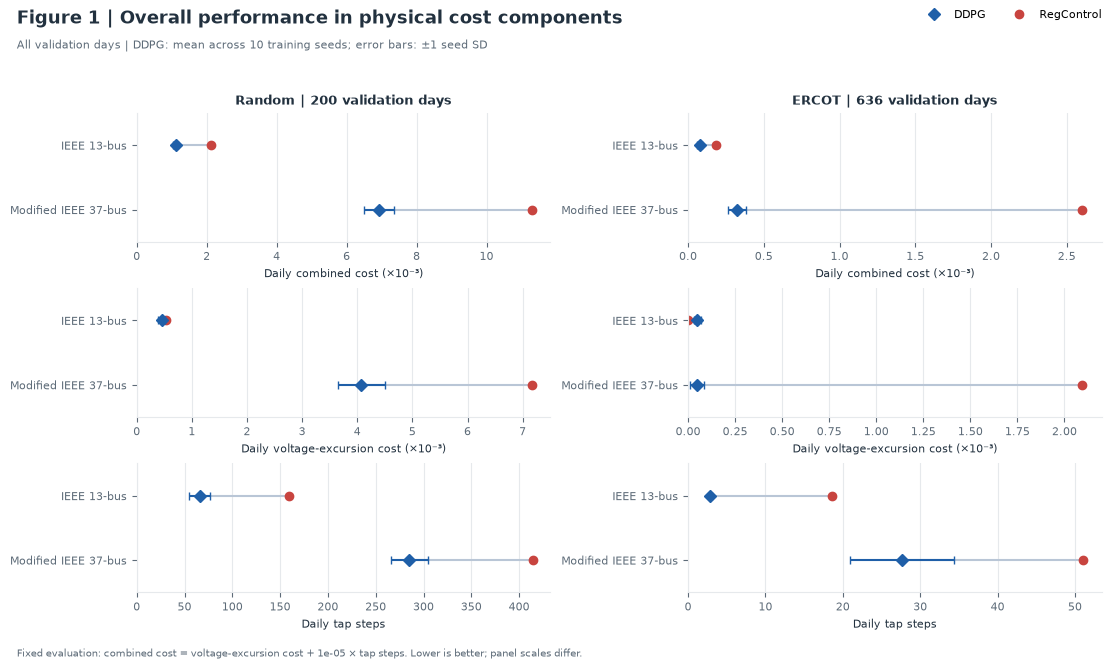

In [5]:
plot_overall(cases);

*Absolute performance separates voltage violations from tap movement.*

### Figure 2: relative improvement against RegControl

RegControl is the 100% reference in each case. Each label states the direction of the change.

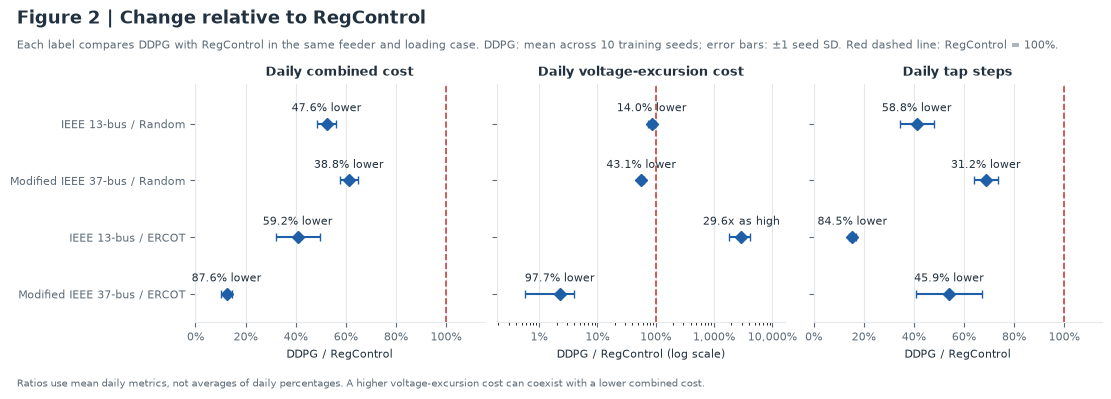

In [6]:
plot_relative(cases);

*Relative comparisons show the size and direction of each performance difference.*

The table lists the values behind Figures 1 and 2.

In [7]:
show_summary_table(cases)

Case,Metric,DDPG seed mean,±1 seed SD,RegControl,DDPG against RegControl
IEEE 13-bus / Random,Daily combined cost (×10⁻³),1.1122,0.0816,2.1238,47.6% lower
IEEE 13-bus / Random,Daily voltage-excursion cost (×10⁻³),0.4539,0.0668,0.5275,14.0% lower
IEEE 13-bus / Random,Daily tap steps,65.84,10.71,159.63,58.8% lower
Modified IEEE 37-bus / Random,Daily combined cost (×10⁻³),6.9277,0.4167,11.3105,38.8% lower
Modified IEEE 37-bus / Random,Daily voltage-excursion cost (×10⁻³),4.0743,0.4245,7.1635,43.1% lower
Modified IEEE 37-bus / Random,Daily tap steps,285.33,19.25,414.69,31.2% lower
IEEE 13-bus / ERCOT,Daily combined cost (×10⁻³),0.0765,0.0164,0.1874,59.2% lower
IEEE 13-bus / ERCOT,Daily voltage-excursion cost (×10⁻³),0.0477,0.0187,0.0016,29.6x as high
IEEE 13-bus / ERCOT,Daily tap steps,2.89,0.23,18.58,84.5% lower
Modified IEEE 37-bus / ERCOT,Daily combined cost (×10⁻³),0.3239,0.0579,2.6032,87.6% lower


## Argument 2: how the 24-hour controller achieves the trade-off

Figures 3 and 4 show one real DDPG run and RegControl on the same day, load profile, and neutral start.
A lower combined cost does not necessarily mean fewer voltage violations.
Changing `PLOT_DAY` or `PLOT_SEED` only changes this display.

Do not read this day as an average or as typical performance.

### Figure 3: aligned 24-hour operation

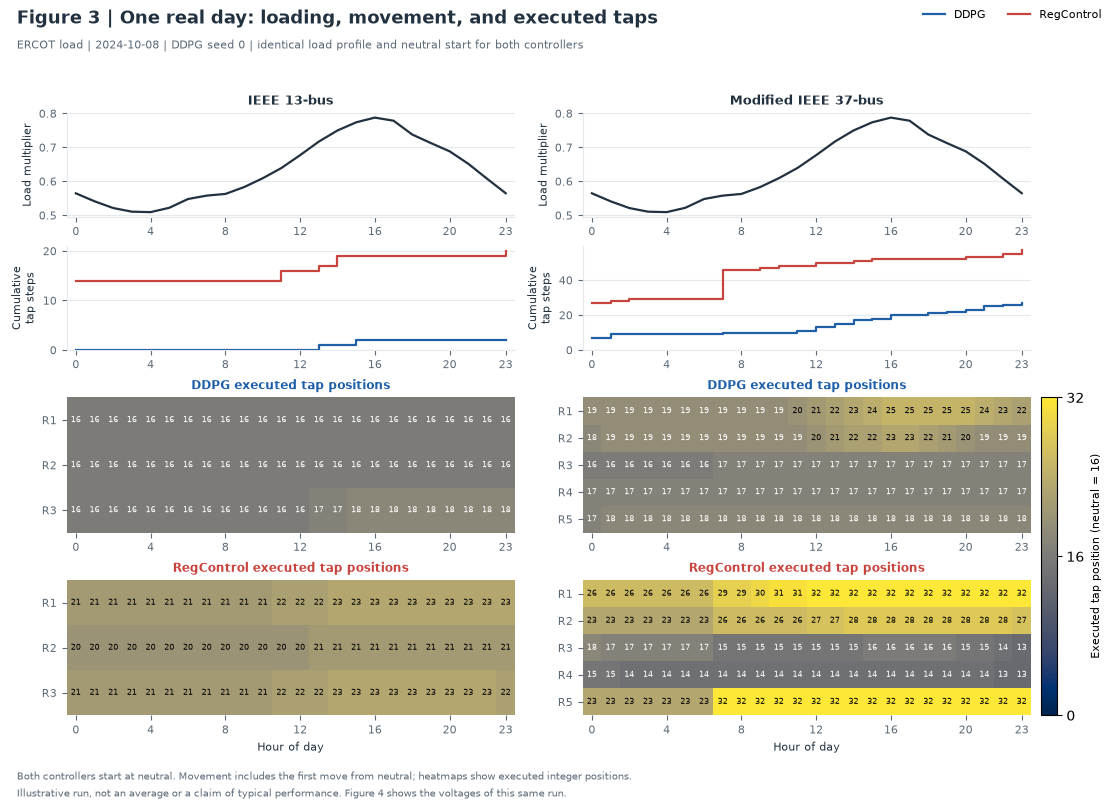

In [8]:
plot_day_operation(cases, DAY_LOADING, PLOT_DAY, PLOT_SEED);

*Daily operation connects load changes with executed actions and accumulated movement.*

### Figure 4: actual voltage ranges and excursions

The objective penalizes voltages outside the green band; the band is not a hard constraint.

Do not interpret the shaded area as the numerical voltage-excursion cost.

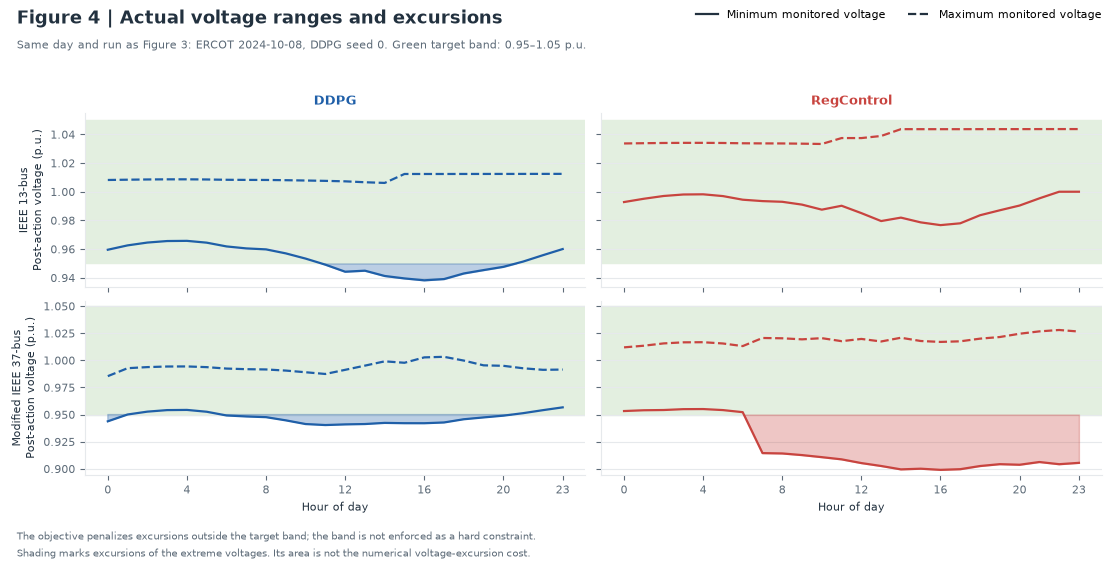

In [9]:
plot_day_voltage(cases, DAY_LOADING, PLOT_DAY, PLOT_SEED);

*Physical voltage ranges reveal the violations underlying the cost trade-off.*

## Argument 3: consistency across validation days

Figures 5 and 6 compare the seed-mean DDPG daily combined cost with RegControl on every validation day.
Counts and savings describe the mean across seeds.

Do not read a count as every seed having a lower cost on those days.

### Figure 5: paired daily combined costs

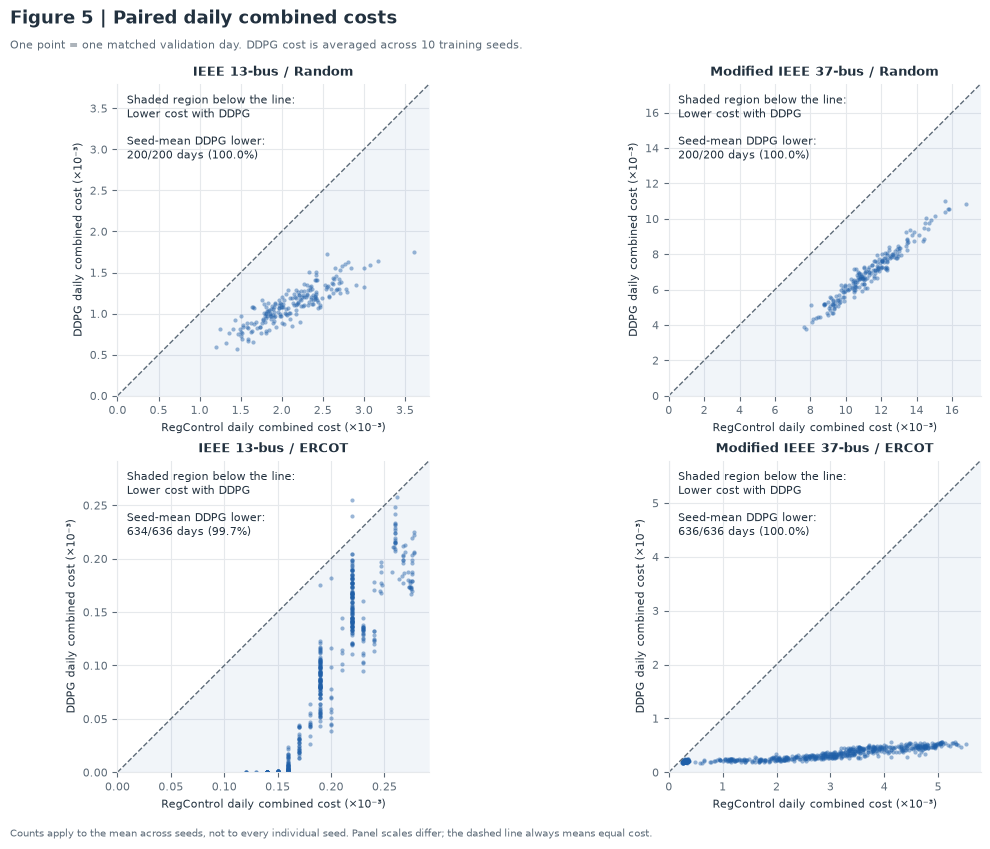

In [10]:
plot_paired_days(cases);

*Paired daily comparisons show how broadly the average advantage holds.*

### Figure 6: daily savings with a distribution summary

Saving equals RegControl cost minus seed-mean DDPG cost. ERCOT panels use calendar dates; Random panels use day indices.
The series and boxplots describe variation across days; the shaded band shows seed spread.

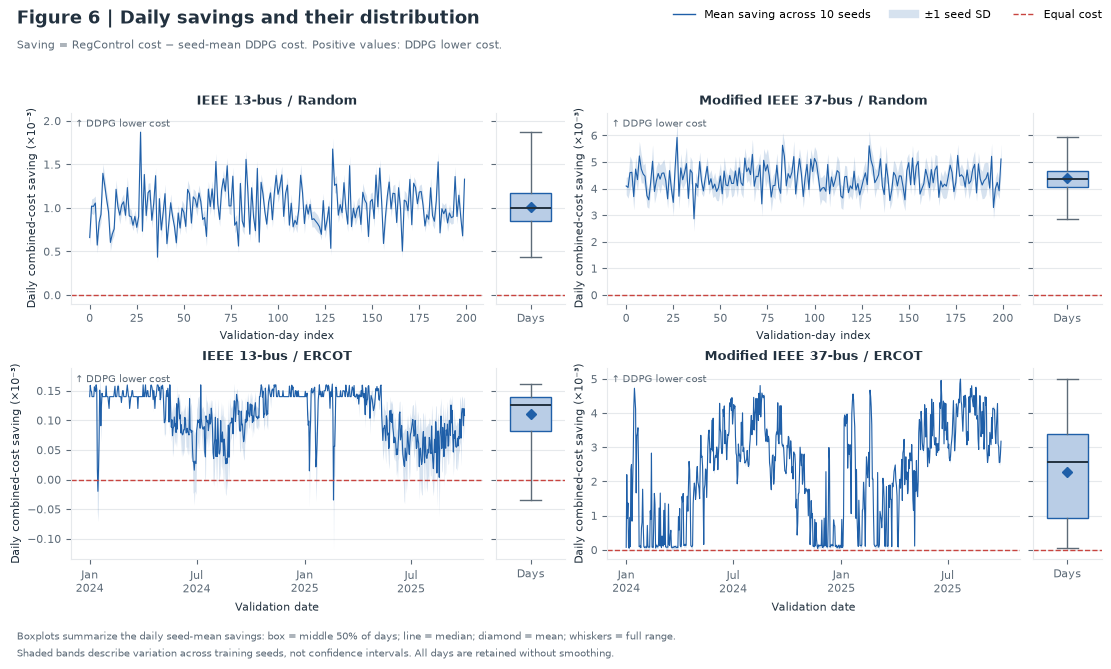

In [11]:
plot_daily_savings(cases);

*Daily savings and their distribution reveal typical improvements and unfavourable cases.*

## Supplementary analysis: adjusting operating preferences

Figure 7 shows how α and β move the operating point on the ERCOT validation days.
The vertical axis is the mean absolute deviation from 1.0 p.u., not the excursion cost.

### Figure 7: voltage deviation against tap movement

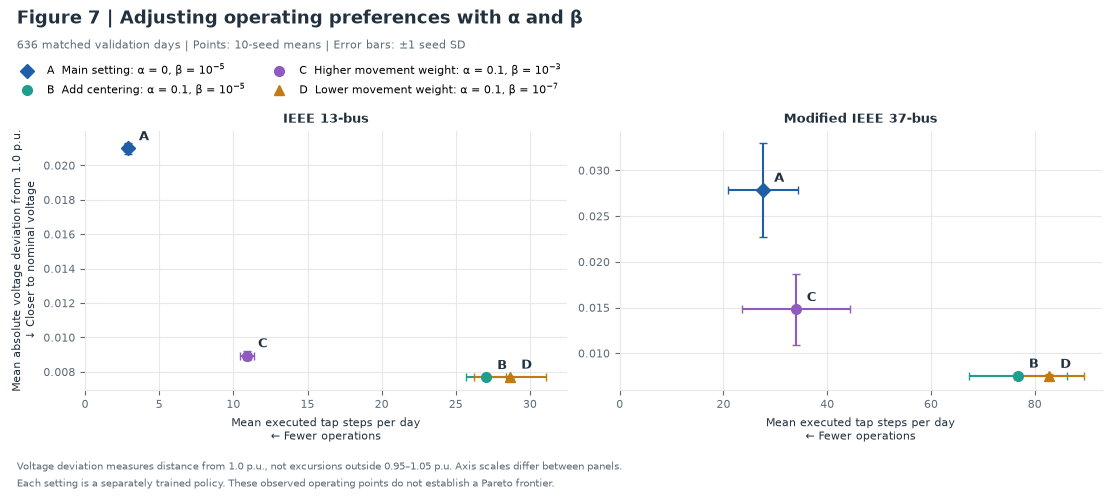

In [12]:
plot_preferences(settings, descriptions);

*Mean voltage deviation versus daily tap movement for different reward weights; error bars indicate ±1 standard deviation across training seeds.*

In [13]:
show_preference_summary(settings, descriptions, STEPS)

Setting,Feeder,Mean tap steps per day,±1 seed SD (steps),Mean absolute deviation (p.u.),±1 seed SD (p.u.)
"A: Main setting: α = 0, β = 10⁻⁵",IEEE 13-bus,2.89,0.23,0.02098,0.00033
"A: Main setting: α = 0, β = 10⁻⁵",Modified IEEE 37-bus,27.63,6.71,0.02785,0.00517
"B: Add centering: α = 0.1, β = 10⁻⁵",IEEE 13-bus,27.04,1.36,0.00768,0.00003
"B: Add centering: α = 0.1, β = 10⁻⁵",Modified IEEE 37-bus,76.74,9.47,0.00752,0.00018
"C: Higher movement weight: α = 0.1, β = 10⁻³",IEEE 13-bus,10.92,0.48,0.00894,0.00027
"C: Higher movement weight: α = 0.1, β = 10⁻³",Modified IEEE 37-bus,33.92,10.39,0.01480,0.00392
"D: Lower movement weight: α = 0.1, β = 10⁻⁷",IEEE 13-bus,28.66,2.41,0.00770,0.00005
"D: Lower movement weight: α = 0.1, β = 10⁻⁷",Modified IEEE 37-bus,82.78,6.70,0.00749,0.00019


A → B (add nominal-voltage centering at fixed β), IEEE 13-bus: mean voltage deviation is lower and tap movement is higher.

A → B (add nominal-voltage centering at fixed β), Modified IEEE 37-bus: mean voltage deviation is lower and tap movement is higher.

B → C (increase the movement weight at fixed α), IEEE 13-bus: mean voltage deviation is higher and tap movement is lower.

B → C (increase the movement weight at fixed α), Modified IEEE 37-bus: mean voltage deviation is higher and tap movement is lower.

B → D (decrease the movement weight at fixed α), IEEE 13-bus: mean voltage deviation is higher and tap movement is higher.

B → D (decrease the movement weight at fixed α), Modified IEEE 37-bus: mean voltage deviation is lower and tap movement is higher.

These separately trained policies illustrate alternative operating compromises. They do not establish a Pareto frontier.

## Supplementary material: individual seeds

Each row is one training run averaged over all validation days.
Do not rank seeds or select a seed from this table.

In [14]:
show_seed_table(cases)

Seed,Daily combined cost (×10⁻³),Daily voltage-excursion cost (×10⁻³),Daily tap steps
0,1.1504,0.4236,72.68
1,1.0862,0.4877,59.85
2,1.3015,0.4154,88.61
3,1.1409,0.4618,67.91
4,1.0456,0.4373,60.83
5,1.0267,0.4428,58.39
6,1.1337,0.3865,74.72
7,1.0279,0.4281,59.98
8,1.1339,0.6278,50.61
9,1.0757,0.4277,64.80


Seed,Daily combined cost (×10⁻³),Daily voltage-excursion cost (×10⁻³),Daily tap steps
0,6.7129,3.7817,293.12
1,6.9846,4.1150,286.96
2,6.7616,3.9107,285.08
3,6.8774,4.1977,267.96
4,6.8060,3.7502,305.58
5,7.1098,4.0962,301.37
6,6.3922,3.8581,253.41
7,7.0843,3.9265,315.78
8,7.9389,5.2089,273.00
9,6.6090,3.8984,271.06


Seed,Daily combined cost (×10⁻³),Daily voltage-excursion cost (×10⁻³),Daily tap steps
0,0.0679,0.0372,3.07
1,0.0815,0.0534,2.81
2,0.0542,0.0216,3.27
3,0.0658,0.0362,2.96
4,0.0951,0.0691,2.60
5,0.0655,0.0350,3.04
6,0.0935,0.0660,2.75
7,0.0726,0.0439,2.86
8,0.1048,0.0799,2.49
9,0.0645,0.0343,3.02


Seed,Daily combined cost (×10⁻³),Daily voltage-excursion cost (×10⁻³),Daily tap steps
0,0.2857,0.0502,23.56
1,0.2919,0.0353,25.67
2,0.2865,0.0295,25.70
3,0.3412,0.0213,31.99
4,0.2789,0.0360,24.29
5,0.3884,0.0252,36.32
6,0.4445,0.0626,38.19
7,0.2571,0.0409,21.62
8,0.3146,0.1434,17.12
9,0.3496,0.0314,31.82


## Conclusions

In [15]:
show_conclusions(cases)

**IEEE 13-bus / Random.** Against RegControl, DDPG has daily combined cost 47.6% lower, daily voltage-excursion cost 14.0% lower, daily tap steps 58.8% lower. The seed-mean DDPG combined cost is lower on 200 of 200 days, equal on 0, and higher on 0.

**Modified IEEE 37-bus / Random.** Against RegControl, DDPG has daily combined cost 38.8% lower, daily voltage-excursion cost 43.1% lower, daily tap steps 31.2% lower. The seed-mean DDPG combined cost is lower on 200 of 200 days, equal on 0, and higher on 0.

**IEEE 13-bus / ERCOT.** Against RegControl, DDPG has daily combined cost 59.2% lower, daily voltage-excursion cost 29.6x as high, daily tap steps 84.5% lower. The seed-mean DDPG combined cost is lower on 634 of 636 days, equal on 0, and higher on 2.

**Modified IEEE 37-bus / ERCOT.** Against RegControl, DDPG has daily combined cost 87.6% lower, daily voltage-excursion cost 97.7% lower, daily tap steps 45.9% lower. The seed-mean DDPG combined cost is lower on 636 of 636 days, equal on 0, and higher on 0.

These statements describe 10 training seeds on the saved validation split. They use means across seeds and do not state that every seed has a lower cost.

## Review note: the IEEE 13-bus / ERCOT case

This note explains the unfavourable voltage result of this case and lists options for review.
The numbers are static text, calculated from the saved rows of seeds 0 to 9 on the validation split.
Make sure to recalculate them after any change to `SEEDS`, `SPLIT`, or the runs.

### What the figures show

- Figure 2 labels the DDPG voltage-excursion cost as 29.6x as high as RegControl in this case.
- Figure 1 shows why the ratio is large: the RegControl voltage-excursion cost is close to zero.
- Figure 1 also shows that RegControl spends 18.6 tap steps per day against 2.9 for DDPG.
- Figures 3 and 4 show one such day: DDPG seed 0 moves two steps and stays below 0.95 p.u. in ten hourly samples (hours 11 to 20).
- Figures 5 and 6 keep the two days on which the seed-mean DDPG combined cost is higher.

### Cost breakdown

Daily means over 636 validation days, in units of 10⁻³ where marked.

| Quantity | RegControl | DDPG, mean of ten seeds |
|---|---|---|
| Voltage-excursion cost (×10⁻³) | 0.0016 | 0.0477 |
| Tap steps per day | 18.6 | 2.9 |
| Switching cost, β × tap steps (×10⁻³) | 0.186 | 0.029 |
| Combined cost (×10⁻³) | 0.187 | 0.077 |

- The ratio 29.6 equals 0.0477 divided by 0.0016.
- DDPG saves about 0.157 × 10⁻³ per day in switching cost and pays about 0.046 × 10⁻³ more in voltage-excursion cost.
- The combined cost is therefore 59.2% lower although the voltage-excursion cost is higher.
- The voltage-excursion cost of single seeds ranges from 0.022 × 10⁻³ to 0.080 × 10⁻³; every seed exceeds RegControl.

### Physical behaviour

- DDPG: the minimum voltage is below 0.95 p.u. in 5,265 to 5,976 of 15,264 validation hours, depending on the seed.
- DDPG: these hours fall on about 450 of 636 days; the lowest voltage of any seed is 0.933 p.u.; no hour exceeds 1.05 p.u.
- RegControl: no hour is below 0.95 p.u.; the maximum voltage exceeds 1.05 p.u. in 606 hours on 64 days.
- RegControl makes 76% of its tap steps in hour 0, when it leaves the neutral start (14.1 of 18.6 steps per day).

The lower combined cost reflects the weighting of the objective with β = 10⁻⁵.
Do not read it as better voltage regulation in this case.

### Comparison with the Figure 7 settings

All rows use the fixed evaluation weight β = 10⁻⁵, so combined costs are comparable.
Hours are counted out of 15,264 and averaged across seeds.

| Controller | Voltage-excursion cost (×10⁻³) | Tap steps per day | Combined cost (×10⁻³) | Hours below 0.95 p.u. | Hours above 1.05 p.u. |
|---|---|---|---|---|---|
| RegControl | 0.0016 | 18.6 | 0.187 | 0 | 606 |
| A: α = 0, β = 10⁻⁵ | 0.0477 | 2.9 | 0.077 | 5,669 | 0 |
| B: α = 0.1, β = 10⁻⁵ | 0.0245 | 27.0 | 0.295 | 0 | 2,690 |
| C: α = 0.1, β = 10⁻³ | 0.0002 | 10.9 | 0.109 | 10 | 107 |
| D: α = 0.1, β = 10⁻⁷ | 0.0262 | 28.7 | 0.313 | 0 | 2,759 |

- Setting C is lower than RegControl on voltage-excursion cost, tap steps, and combined cost in this case.
- The seed with the highest voltage-excursion cost under setting C (0.0005 × 10⁻³) is still below RegControl.
- Setting A has the lowest combined cost among the four tested settings.
- Setting A alone trains on the evaluation objective. Do not read this result as evidence that its training reached the optimum.
- A rough diagnostic check is consistent with the objective favouring few tap steps: raising three regulators by two steps costs about 0.06 × 10⁻³ per day.
- That cost exceeds the 0.048 × 10⁻³ of voltage-excursion cost it could remove. No simulation confirms this check.
- Settings B and D remove the undervoltage but exceed 1.05 p.u. in about 2,700 hours and move more than RegControl.
- Figure 7 plots deviation from 1.0 p.u., so it does not show these excursion counts.

### Options for review

1. Report setting C beside setting A for this case. No new training is needed.
2. Train settings between A and C, for example α from 0.01 to 0.05 at β = 10⁻⁵, or α = 0.1 at β = 10⁻⁴.
3. Add a best-fixed-tap-per-day reference as a diagnostic comparison for setting A.
4. Carry tap positions from one day to the next instead of the daily neutral start.

Notes on the options:

- Setting C was identified after the validation results were read. Make sure to confirm it on the test split.
- Option 3 covers fixed taps only. A lower fixed-tap cost shows that setting A is not optimal.
- Option 3 cannot establish the optimum of the full sequential-control problem.
- Option 4 changes the evaluation protocol and affects every result in this notebook.
- Options 1 and 3 cost the least.
- The parameter `rate` affects only the exponential nominal-voltage deviation. No displayed setting uses it.
- These options are working material for review. They are not additional arguments of the paper.